In [ ]:
import warnings
warnings.filterwarnings(action="ignore", message=r"datetime.datetime.utcnow")

# PERSIAPAN

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Pada laporan praktikum, sisipkan penjelasan singkat mengenai *library* `sklearn` (ambil dari https://scikit-learn.org/stable/) pada **BAB 2** pada bagian metode yang melibatkannya.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
os.chdir('drive/MyDrive/sml') # ganti dengan folder hasil copy kalian

In [ ]:
df_full = pd.read_csv("voters.csv")
df_full.head()

,VoterID,Age,Interest,OnlineHours,FirstTime,StableJob,Community,InfoSource,Education,Candidate
0,1,54.0,6.0,7.0,1.0,No,No,TV,Primary,Paslon_A
1,2,51.0,NaN,NaN,0.0,NaN,No,TV,NaN,Paslon_A
2,3,49.0,8.0,1.0,0.0,Yes,No,SocialMedia,Secondary,Paslon_C
3,4,30.0,4.0,3.0,0.0,Yes,Yes,FriendsFamily,NaN,Paslon_C
4,5,66.0,1.0,4.0,0.0,Yes,Yes,SocialMedia,Tertiary,Paslon_A


Deskripsi:
* **VoterID**: pengenal unik untuk setiap pemilih
* **Age**: usia pemilih (dalam tahun; bilangan bulat, umumnya 17–80)
* **Interest**: skor ketertarikan pemilih pada politik (skala 1–10; nilai lebih tinggi = lebih tertarik)
* **OnlineHours**: rata-rata durasi konsumsi konten politik secara online per minggu (dalam jam; misalnya berita online, video, media sosial politik)
* **FirstTime**: status pemilih pemula ("Yes" = ini pemilu pertama yang diikuti, "No" = sudah pernah ikut pemilu sebelumnya)
* **StableJob**: status pekerjaan tetap pemilih ("Yes" = memiliki pekerjaan tetap, "No" = belum/tidak memiliki pekerjaan tetap)
* **Community**: partisipasi pemilih dalam organisasi/komunitas sosial ("Yes" = aktif dalam organisasi/komunitas, "No" = tidak aktif)
* **InfoSource**: sumber utama informasi politik pemilih ("TV", "OnlineNews", "SocialMedia", atau "FriendsFamily")
* **Education**: tingkat pendidikan terakhir pemilih ("Primary" = SD/sederajat, "Secondary" = SMP/SMA/SMK/sederajat, "Tertiary" = perguruan tinggi)
* **Candidate**: pilihan pasangan calon presiden dalam simulasi ("Paslon_A", "Paslon_B", atau "Paslon_C"; variabel target klasifikasi)

Melihat struktur data mentah

In [ ]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3675 entries, 0 to 3674
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   VoterID      3675 non-null   int64  
 1   Age          3356 non-null   float64
 2   Interest     3355 non-null   float64
 3   OnlineHours  3286 non-null   float64
 4   FirstTime    3317 non-null   float64
 5   StableJob    3322 non-null   object 
 6   Community    3316 non-null   object 
 7   InfoSource   3295 non-null   object 
 8   Education    3346 non-null   object 
 9   Candidate    3675 non-null   object 
dtypes: float64(4), int64(1), object(5)
memory usage: 287.2+ KB


Pemilihan variabel

In [ ]:
df_full.columns

Index(['VoterID', 'Age', 'Interest', 'OnlineHours', 'FirstTime', 'StableJob',
       'Community', 'InfoSource', 'Education', 'Candidate'],
      dtype='object')

In [ ]:
df = df_full.copy()
df = df_full.drop(columns=['VoterID'], axis=1)
df.head()

,Age,Interest,OnlineHours,FirstTime,StableJob,Community,InfoSource,Education,Candidate
0,54.0,6.0,7.0,1.0,No,No,TV,Primary,Paslon_A
1,51.0,NaN,NaN,0.0,NaN,No,TV,NaN,Paslon_A
2,49.0,8.0,1.0,0.0,Yes,No,SocialMedia,Secondary,Paslon_C
3,30.0,4.0,3.0,0.0,Yes,Yes,FriendsFamily,NaN,Paslon_C
4,66.0,1.0,4.0,0.0,Yes,Yes,SocialMedia,Tertiary,Paslon_A


Mempersingkat nama kolom

In [ ]:
df.columns = ['age', 'interest', 'online', 'first', 'job_stable',
       'community', 'info_source', 'edu', 'candidate']
df.head()

,age,interest,online,first,job_stable,community,info_source,edu,candidate
0,54.0,6.0,7.0,1.0,No,No,TV,Primary,Paslon_A
1,51.0,NaN,NaN,0.0,NaN,No,TV,NaN,Paslon_A
2,49.0,8.0,1.0,0.0,Yes,No,SocialMedia,Secondary,Paslon_C
3,30.0,4.0,3.0,0.0,Yes,Yes,FriendsFamily,NaN,Paslon_C
4,66.0,1.0,4.0,0.0,Yes,Yes,SocialMedia,Tertiary,Paslon_A


Mengubah data kategorik yang terbaca numerik oleh Python

In [ ]:
df = df.copy()
for c in ["first"]:
    df[c] = df[c].astype("Int64").astype("object")

In [ ]:
df['first'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 3675 entries, 0 to 3674
Series name: first
Non-Null Count  Dtype 
--------------  ----- 
3317 non-null   object
dtypes: object(1)
memory usage: 28.8+ KB


# EXPLORATORY DATA ANALYSIS

### Ringkasan

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3675 entries, 0 to 3674
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          3356 non-null   float64
 1   interest     3355 non-null   float64
 2   online       3286 non-null   float64
 3   first        3317 non-null   object 
 4   job_stable   3322 non-null   object 
 5   community    3316 non-null   object 
 6   info_source  3295 non-null   object 
 7   edu          3346 non-null   object 
 8   candidate    3675 non-null   object 
dtypes: float64(3), object(6)
memory usage: 258.5+ KB


In [ ]:
df.describe(include = 'number')

,age,interest,online
count,3356.000000,3355.000000,3286.000000
mean,53.040524,6.354993,4.941570
std,33.023437,3.964218,5.915663
min,17.000000,1.000000,0.000000
25%,30.000000,3.000000,2.000000
50%,46.000000,6.000000,3.000000
75%,66.250000,9.000000,6.000000
max,236.000000,20.000000,57.000000


In [ ]:
df.describe(include = ['category', 'object'])

,first,job_stable,community,info_source,edu,candidate
count,3317,3322,3316,3295,3346,3675
unique,2,2,2,4,3,3
top,0,Yes,No,OnlineNews,Secondary,Paslon_C
freq,2255,1929,2018,1111,1661,1359


## Visualisasi

### Univariat

Kategorik

Sebaran Jumlah Responden Menurut Paslon Pilihan


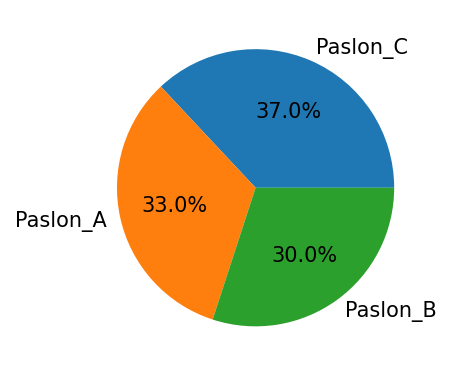

In [ ]:
print('Sebaran Jumlah Responden Menurut Paslon Pilihan')
plt.figure(figsize=(6,3), dpi=150)
df["candidate"].value_counts().plot(kind="pie", autopct="%.1f%%", ylabel="")
plt.show()

Berdasarkan pie chart di atas, proporsi variabel target **cenderung balanced**, sehingga tidak diperlukan penanganan imbalanced data.

Sebaran Responden Berdasarkan Status Pemilih Pertama


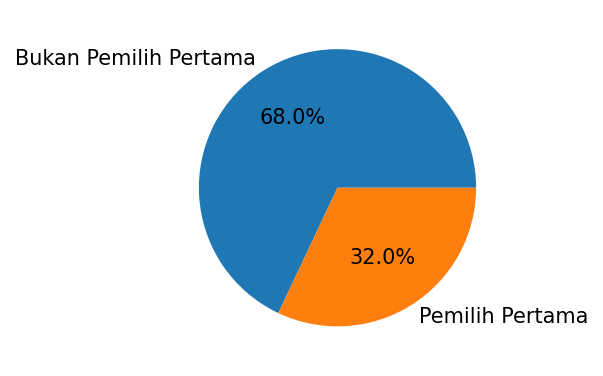

In [ ]:
print('Sebaran Responden Berdasarkan Status Pemilih Pertama')

plt.figure(figsize=(6, 3), dpi=150)
df["first"].map({0: "Bukan Pemilih Pertama", 1: "Pemilih Pertama"}) \
           .value_counts() \
           .plot(kind="pie", autopct="%.1f%%", ylabel="")
plt.show()

Numerik

Sebaran Rata-Rata Durasi Konsumsi Konten Politik Secara Online per Minggu


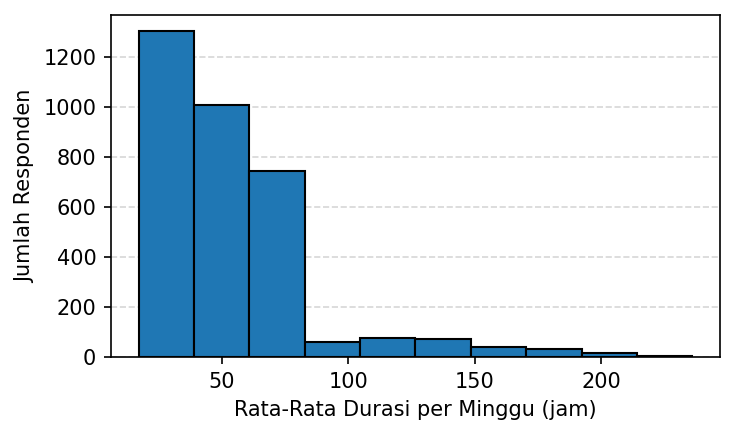

In [ ]:
print("Sebaran Rata-Rata Durasi Konsumsi Konten Politik Secara Online per Minggu")

plt.figure(figsize=(5,3), dpi=150)
plt.hist(df["age"], bins=10, edgecolor="black")

ax = plt.gca()
ax.set_axisbelow(True)
ax.grid(True, axis="y", linestyle="--", alpha=0.5)

plt.xlabel("Rata-Rata Durasi per Minggu (jam)")
plt.ylabel("Jumlah Responden")
plt.tight_layout()
plt.show()

### Bivariat

Numerik vs Kategorik

Sebaran Usia Responden Menurut Pilihan Pasangan Calon Presiden


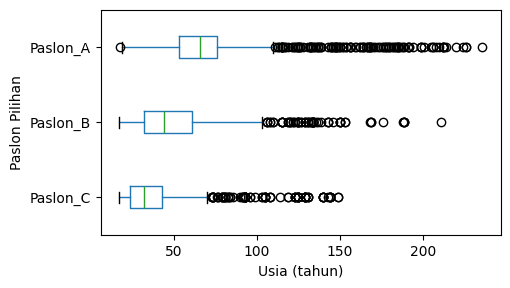

In [ ]:
print("Sebaran Usia Responden Menurut Pilihan Pasangan Calon Presiden")

fig, ax = plt.subplots(figsize=(5, 3), dpi=100)
df.boxplot(column="age", by="candidate", grid=False, vert=False, ax=ax)
ax.invert_yaxis()
ax.set_xlabel("Usia (tahun)")
ax.set_ylabel("Paslon Pilihan")
ax.set_title("")
fig.suptitle("")
plt.show()

Kategorik vs Kategorik

Perbandingan Jumlah Responden Menurut Sumber Utama Informasi Politik dan Pilihan Pasangan Calon


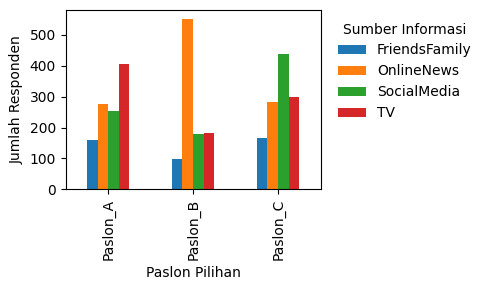

In [ ]:
print("Perbandingan Jumlah Responden Menurut Sumber Utama Informasi Politik dan Pilihan Pasangan Calon")

pd.crosstab(df["candidate"], df["info_source"]).plot(kind="bar", figsize=(5, 3))
plt.xlabel("Paslon Pilihan")
plt.ylabel("Jumlah Responden")
plt.legend(title="Sumber Informasi", bbox_to_anchor=(1.02, 1),
    loc="upper left", frameon=False,
)
plt.tight_layout()
plt.show()

# PREPROCESSING

### Missing Value

In [ ]:
print('Total Missing Value')
print(df.isnull().sum())

Total Missing Value
age            319
interest       320
online         389
first          358
job_stable     353
community      359
info_source    380
edu            329
candidate        0
dtype: int64


In [ ]:
df_lengkap = df.copy()

Jika terdapat missing value pada data, maka terdapat dua opsi untuk menanganinya:


1. Imputasi pada sel data yang kosong dengan suatu nilai (misal: mean/median/modus) pada kolom yang mengandung missing value

In [ ]:
# # 1. Contoh penanganan missing value menggunakan rata-rata
col_with_mis_val = ['age', 'interest', 'online']
for col in col_with_mis_val:
  df_lengkap[col] = df_lengkap[col].fillna(df_lengkap[col].mean())

2. Menghapus baris yang mengandung missing value

In [ ]:
# 2. Contoh penanganan missing value dengan menghapus baris yang mengandung missing value
df_lengkap = df_lengkap.dropna(axis=0)

In [ ]:
print('Total Missing Value')
print(df_lengkap.isnull().sum())

Total Missing Value
age            0
interest       0
online         0
first          0
job_stable     0
community      0
info_source    0
edu            0
candidate      0
dtype: int64


### Outlier

In [ ]:
def cek_outlier(df, figsize=(4, 1), dpi=150):
    kolom = df.select_dtypes(include=[np.number]).columns
    if len(kolom) == 0:
        print("Tidak ada kolom numerik.")
        return

    df_checked = df[kolom]
    df_checked.plot(
        kind="box",
        subplots=True,
        layout=(len(kolom), 1),
        figsize=(figsize[0], len(kolom) * figsize[1]),
        sharex=False,
        vert=False,
    )

    fig = plt.gcf()
    fig.set_dpi(dpi)
    fig.subplots_adjust(hspace=0.6)

    plt.show()

Boxplot Seluruh Variabel Numerik Sebelum Pembersihan Outlier


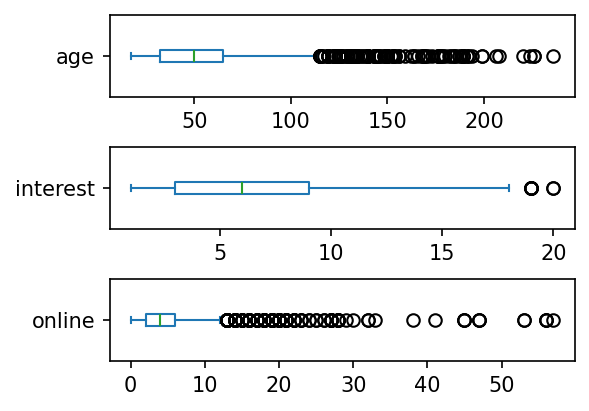

In [ ]:
print("Boxplot Seluruh Variabel Numerik Sebelum Pembersihan Outlier")
cek_outlier(df_lengkap)

Hapus outlier (hanya gunakan jika diperlukan)

In [ ]:
def hapus_outlier(df, kolom=None, max_iter=1):
    kolom = df.select_dtypes(include=[np.number]).columns

    df_clean = df.copy()
    for i in range(max_iter):
        before = df_clean.shape[0]

        mask = pd.Series(True, index=df_clean.index)
        for c in kolom:
            Q1, Q3 = df_clean[c].quantile([0.25, 0.75])
            IQR = Q3 - Q1
            mask &= df_clean[c].between(Q1 - 1.5*IQR, Q3 + 1.5*IQR)

        df_clean = df_clean[mask]
        after = df_clean.shape[0]

        if before == after:  # berhenti kalau tidak ada perubahan
            break
        print(f'Iterasi {i+1}: {before} -> {after} sampel')

    return df_clean

In [ ]:
df_bersih = df_lengkap.copy()
df_bersih = hapus_outlier(df_bersih, max_iter=10)
print()
df_bersih.info()

Iterasi 1: 2217 -> 1982 sampel
Iterasi 2: 1982 -> 1868 sampel
Iterasi 3: 1868 -> 1865 sampel

<class 'pandas.core.frame.DataFrame'>
Index: 1865 entries, 0 to 3674
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          1865 non-null   float64
 1   interest     1865 non-null   float64
 2   online       1865 non-null   float64
 3   first        1865 non-null   object 
 4   job_stable   1865 non-null   object 
 5   community    1865 non-null   object 
 6   info_source  1865 non-null   object 
 7   edu          1865 non-null   object 
 8   candidate    1865 non-null   object 
dtypes: float64(3), object(6)
memory usage: 145.7+ KB


Boxplot Seluruh Variabel Numerik Setelah Pembersihan Outlier


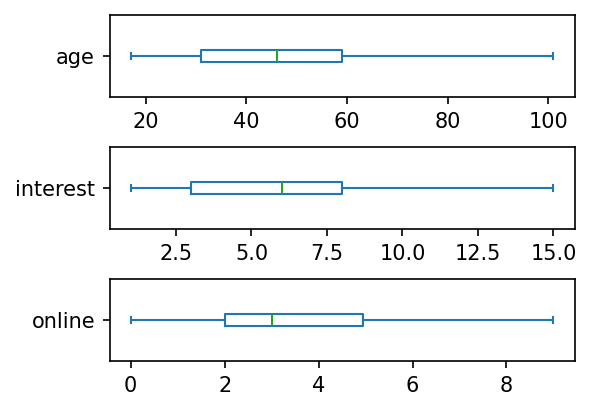

In [ ]:
print("Boxplot Seluruh Variabel Numerik Setelah Pembersihan Outlier")
cek_outlier(df_bersih)

### Data Duplikat

In [ ]:
print(df_bersih.duplicated().sum(), 'baris terduplikat')
display(df_bersih[df_bersih.duplicated()].head())

559 baris terduplikat


,age,interest,online,first,job_stable,community,info_source,edu,candidate
115,19.0,2.0,7.00000,1,Yes,No,OnlineNews,Secondary,Paslon_C
138,32.0,3.0,4.94157,0,Yes,No,TV,Secondary,Paslon_C
256,19.0,2.0,7.00000,1,Yes,No,OnlineNews,Secondary,Paslon_C
336,23.0,10.0,0.00000,0,No,Yes,OnlineNews,Primary,Paslon_B
351,38.0,10.0,1.00000,0,No,No,OnlineNews,Secondary,Paslon_B


Hapus data yang terduplikat

In [ ]:
df_siap = df_bersih.copy()
df_siap.drop_duplicates(inplace=True)
print(df_siap.duplicated().sum(), 'baris terduplikat\n')
df_siap.info()

0 baris terduplikat

<class 'pandas.core.frame.DataFrame'>
Index: 1306 entries, 0 to 3668
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          1306 non-null   float64
 1   interest     1306 non-null   float64
 2   online       1306 non-null   float64
 3   first        1306 non-null   object 
 4   job_stable   1306 non-null   object 
 5   community    1306 non-null   object 
 6   info_source  1306 non-null   object 
 7   edu          1306 non-null   object 
 8   candidate    1306 non-null   object 
dtypes: float64(3), object(6)
memory usage: 102.0+ KB


# SPLITTING DATA & TRANSFORMASI

### Splitting Data

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# Pisahkan fitur (X) dan target (y)
col_y = 'candidate'
X = df_siap.drop(columns=col_y)
y = df_siap[col_y]

print('Variabel prediktor:', ', '.join(X.columns.values))
print('Variabel respons/target:', col_y)

Variabel prediktor: age, interest, online, first, job_stable, community, info_source, edu
Variabel respons/target: candidate


In [ ]:
# Split train (80%) dan test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

print("Ukuran data train:", X_train.shape[0], 'baris')
print("Ukuran data test :", X_test.shape[0], 'baris')

Ukuran data train: 1044 baris
Ukuran data test : 262 baris


### One-Hot Encoding (untuk kategorikal)

In [ ]:
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns

X_train_dum = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype='uint8')
X_test_dum = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype='uint8')
X_test_dum = X_test_dum.reindex(columns=X_train_dum.columns, fill_value=0)
X_train_dum.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1044 entries, 2432 to 2948
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      1044 non-null   float64
 1   interest                 1044 non-null   float64
 2   online                   1044 non-null   float64
 3   first_1                  1044 non-null   uint8  
 4   job_stable_Yes           1044 non-null   uint8  
 5   community_Yes            1044 non-null   uint8  
 6   info_source_OnlineNews   1044 non-null   uint8  
 7   info_source_SocialMedia  1044 non-null   uint8  
 8   info_source_TV           1044 non-null   uint8  
 9   edu_Secondary            1044 non-null   uint8  
 10  edu_Tertiary             1044 non-null   uint8  
dtypes: float64(3), uint8(8)
memory usage: 40.8 KB


### Standardisasi (untuk numerik)

**Catatan:**
* Jika terdapat variabel prediktor bertipe numerik pada suatu kasus klasifikasi, direkomendasikan untuk menstandardisasi variabel tersebut (mean=0, std=1) pada data training (data testing menyesuaikan) pada beberapa model.
* Model yang mengharuskan hal tersebut antara lain: logistic regression, SVM, k-NN, hingga neural network; sedangkan model-model berbasis pohon (decision tree, random forest) dan boosting (gradient boosting, XGboost, LightGBM) tidak terlalu mempermasalahkan apakah variabel tersebut distandardisasi ataupun tidak.
* Pada praktikum ini, digunakan data yang variabel numeriknya telah distandardsasi agar meminimalkan kesalahan penggunaan data antarmodel serta memastikan perbandingan metrik evaluasi antarmodel lebih adil pada bagian akhir.

In [ ]:
from sklearn.preprocessing import StandardScaler

num_cols = X_train.select_dtypes(include=[np.number]).columns

scaler = StandardScaler()
scaler.fit(X_train_dum[num_cols])

X_train_std = X_train_dum.copy()
X_test_std  = X_test_dum.copy()
X_train_std[num_cols] = scaler.transform(X_train_dum[num_cols])
X_test_std[num_cols]  = scaler.transform(X_test_dum[num_cols])

In [ ]:
stats_train = pd.DataFrame({
    "mean_before": X_train_dum[num_cols].mean(),
    "std_before":  X_train_dum[num_cols].std(ddof=0),
    "mean_after":  X_train_std[num_cols].mean(),
    "std_after":   X_train_std[num_cols].std(ddof=0),
}).round(3)

# Cek hasil scaling pada data training
stats_train

,mean_before,std_before,mean_after,std_after
age,49.106,18.190,0.0,1.0
interest,5.656,2.967,-0.0,1.0
online,3.275,2.189,0.0,1.0


# KLASIFIKASI (BALANCED DATA)

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, recall_score, precision_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV

## k-Nearest Neighbors

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

### Training

#### Tanpa tuning parameter

In [ ]:
# Membuat model
model_knn = KNeighborsClassifier(n_neighbors = 25)
# Train model
model_knn.fit(X_train_std, y_train)

KNeighborsClassifier(n_neighbors=25)

#### Dengan tuning parameter

In [ ]:
param_knn = {
    "n_neighbors": range(1, 51)
    } # 1 s.d. 50

grid_knn = GridSearchCV(
    KNeighborsClassifier(),
    param_knn,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

grid_knn.fit(X_train_std, y_train)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'n_neighbors': range(1, 51)}, scoring='accuracy')

In [ ]:
print("Best params :", grid_knn.best_params_)
print("Best CV acc :", grid_knn.best_score_)

Best params : {'n_neighbors': 33}
Best CV acc : 0.6868099006256901


In [ ]:
model_knn = KNeighborsClassifier(**grid_knn.best_params_)
model_knn.fit(X_train_std, y_train)

KNeighborsClassifier(n_neighbors=33)

### Evaluasi

In [ ]:
y_pred_knn_train = model_knn.predict(X_train_std)
y_pred_knn_test  = model_knn.predict(X_test_std)

train_acc_knn = accuracy_score(y_pred_knn_train, y_train)
test_acc_knn = accuracy_score(y_pred_knn_test, y_test)

print(f"Train Accuracy : {train_acc_knn:.04f}")
print(f"Test Accuracy  : {test_acc_knn:.04f}")

Train Accuracy : 0.6983
Test Accuracy  : 0.6450


In [ ]:
labels = np.unique(y_test)
cm_knn = confusion_matrix(y_test, y_pred_knn_test, labels=labels)
cm_knn

array([[107,   2,   8],
       [ 37,  17,  16],
       [ 24,   6,  45]])

In [ ]:
print("Sensitivity & Specificity per class:")

sensitivity_knn = []
specificity_knn = []

for i, cls in enumerate(labels):
    tp = cm_knn[i, i]
    fn = cm_knn[i, :].sum() - tp
    fp = cm_knn[:, i].sum() - tp
    tn = cm_knn.sum() - tp - fn - fp

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    sensitivity_knn += [sensitivity]
    specificity_knn += [specificity]

    print(f"Jika kategori {cls} adalah kelas positif -> Sensitivity: {sensitivity:.3f} | Specificity: {specificity:.3f}")

Sensitivity & Specificity per class:
Jika kategori Paslon_A adalah kelas positif -> Sensitivity: 0.915 | Specificity: 0.579
Jika kategori Paslon_B adalah kelas positif -> Sensitivity: 0.243 | Specificity: 0.958
Jika kategori Paslon_C adalah kelas positif -> Sensitivity: 0.600 | Specificity: 0.872


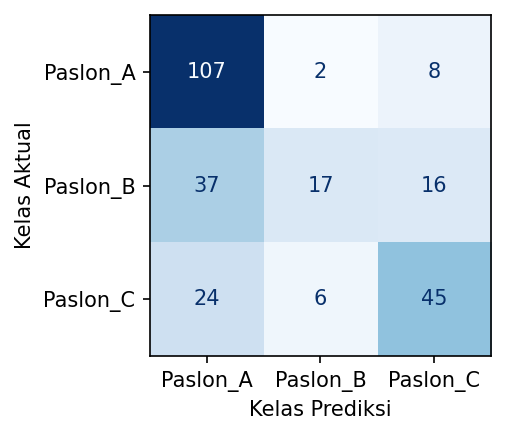

In [ ]:
fig, ax = plt.subplots(figsize=(5, 3), dpi=150)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=labels)
disp.plot(values_format=".0f", cmap="Blues", colorbar=False, ax=ax)

ax.set_xlabel("Kelas Prediksi")
ax.set_ylabel("Kelas Aktual")

plt.tight_layout()
plt.show()

### Prediksi

Sebagai contoh, dilakukan prediksi menggunakan data baru sebagai berikut:

In [ ]:
data_baru = {
    "age": 21,
    "interest": 4,              # misal skala 1–5
    "online": 5,                # misal jam online per hari
    "first_1": 1,               # pemilih pertama kali
    "job_stable_Yes": 0,        # pekerjaan belum stabil
    "community_Yes": 1,         # aktif komunitas
    "info_source_OnlineNews": 0,
    "info_source_SocialMedia": 1,
    "info_source_TV": 0,
    "edu_Secondary": 0,
    "edu_Tertiary": 1,          # pendidikan tinggi
}

X_new = pd.DataFrame([data_baru])

y_pred_new = model_knn.predict(X_new)
y_proba_new = model_knn.predict_proba(X_new)

print("Prediksi pilihan paslon :", y_pred_new[0])
print("Prob tiap kelas         :", y_proba_new[0])

Prediksi pilihan paslon : Paslon_A
Prob tiap kelas         : [0.63636364 0.18181818 0.18181818]


## Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier

### Training

#### Tanpa tuning parameter

In [ ]:
# Membuat model
model_dct = DecisionTreeClassifier(min_samples_split=30)
# Train model
model_dct.fit(X_train_std, y_train)

DecisionTreeClassifier(min_samples_split=30)

#### Dengan tuning parameter

In [ ]:
param_dct = {
    "min_samples_split": [5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
}

grid_dct = GridSearchCV(
    DecisionTreeClassifier(),
    param_dct,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

grid_dct.fit(X_train_std, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(), n_jobs=-1,
             param_grid={'min_samples_leaf': [1, 2, 4, 8],
                         'min_samples_split': [5, 10, 20]},
             scoring='accuracy')

In [ ]:
print("Best params :", grid_dct.best_params_)
print("Best CV acc :", grid_dct.best_score_)

Best params : {'min_samples_leaf': 2, 'min_samples_split': 10}
Best CV acc : 0.6120767390504233


In [ ]:
model_dct = DecisionTreeClassifier(**grid_dct.best_params_)
model_dct.fit(X_train_std, y_train)

DecisionTreeClassifier(min_samples_leaf=2, min_samples_split=10)

### Evaluasi

In [ ]:
y_pred_dct_train = model_dct.predict(X_train_std)
y_pred_dct_test  = model_dct.predict(X_test_std)

train_acc_dct = accuracy_score(y_pred_dct_train, y_train)
test_acc_dct = accuracy_score(y_pred_dct_test, y_test)

print(f"Train Accuracy : {train_acc_dct:.04f}")
print(f"Test Accuracy  : {test_acc_dct:.04f}")

Train Accuracy : 0.8123
Test Accuracy  : 0.5878


In [ ]:
labels = np.unique(y_test)
cm_dct = confusion_matrix(y_test, y_pred_dct_test, labels=labels)
cm_dct

array([[91, 17,  9],
       [25, 25, 20],
       [18, 19, 38]])

In [ ]:
print("Sensitivity & Specificity per class:")

sensitivity_dct = []
specificity_dct = []

for i, cls in enumerate(labels):
    tp = cm_dct[i, i]
    fn = cm_dct[i, :].sum() - tp
    fp = cm_dct[:, i].sum() - tp
    tn = cm_dct.sum() - tp - fn - fp

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    sensitivity_dct += [sensitivity]
    specificity_dct += [specificity]

    print(f"Jika kategori {cls} adalah kelas positif -> Sensitivity: {sensitivity:.3f} | Specificity: {specificity:.3f}")

Sensitivity & Specificity per class:
Jika kategori Paslon_A adalah kelas positif -> Sensitivity: 0.778 | Specificity: 0.703
Jika kategori Paslon_B adalah kelas positif -> Sensitivity: 0.357 | Specificity: 0.812
Jika kategori Paslon_C adalah kelas positif -> Sensitivity: 0.507 | Specificity: 0.845


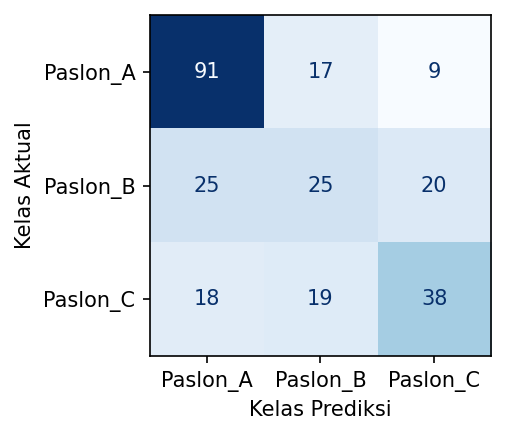

In [ ]:
fig, ax = plt.subplots(figsize=(5, 3), dpi=150)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_dct, display_labels=labels)
disp.plot(values_format=".0f", cmap="Blues", colorbar=False, ax=ax)

ax.set_xlabel("Kelas Prediksi")
ax.set_ylabel("Kelas Aktual")

plt.tight_layout()
plt.show()

### Prediksi

Sebagai contoh, dilakukan prediksi menggunakan data baru sebagai berikut:

In [ ]:
data_baru = {
    "age": 21,
    "interest": 4,              # misal skala 1–5
    "online": 5,                # misal jam online per hari
    "first_1": 1,               # pemilih pertama kali
    "job_stable_Yes": 0,        # pekerjaan belum stabil
    "community_Yes": 1,         # aktif komunitas
    "info_source_OnlineNews": 0,
    "info_source_SocialMedia": 1,
    "info_source_TV": 0,
    "edu_Secondary": 0,
    "edu_Tertiary": 1,          # pendidikan tinggi
}

X_new = pd.DataFrame([data_baru])

y_pred_new = model_dct.predict(X_new)
y_proba_new = model_dct.predict_proba(X_new)

print("Prediksi pilihan paslon :", y_pred_new[0])
print("Prob tiap kelas         :", y_proba_new[0])

Prediksi pilihan paslon : Paslon_C
Prob tiap kelas         : [0.22222222 0.22222222 0.55555556]


## Support Vector Machine

In [ ]:
from sklearn.svm import SVC

### Training

#### Tanpa tuning parameter

In [ ]:
# Membuat model
model_svm = SVC(kernel = "linear", probability=True)
# Train model
model_svm.fit(X_train_std, y_train)

SVC(kernel='linear', probability=True)

#### Dengan tuning parameter

In [ ]:
param_svm = {
    "kernel": ["linear", "rbf"],
    "C": [0.1, 1, 10, 100],
}

grid_svm = GridSearchCV(
    SVC(),
    param_svm,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

grid_svm.fit(X_train_std, y_train)

GridSearchCV(cv=5, estimator=SVC(), n_jobs=-1,
             param_grid={'C': [0.1, 1, 10, 100], 'kernel': ['linear', 'rbf']},
             scoring='accuracy')

In [ ]:
print("Best params :", grid_svm.best_params_)
print("Best CV acc :", grid_svm.best_score_)

Best params : {'C': 0.1, 'kernel': 'linear'}
Best CV acc : 0.6925653294074346


In [ ]:
model_svm = SVC(**grid_svm.best_params_, probability=True)
model_svm.fit(X_train_std, y_train)

SVC(C=0.1, kernel='linear', probability=True)

### Evaluasi

In [ ]:
y_pred_svm_train = model_svm.predict(X_train_std)
y_pred_svm_test  = model_svm.predict(X_test_std)

train_acc_svm = accuracy_score(y_pred_svm_train, y_train)
test_acc_svm = accuracy_score(y_pred_svm_test, y_test)

print(f"Train Accuracy : {train_acc_svm:.04f}")
print(f"Test Accuracy  : {test_acc_svm:.04f}")

Train Accuracy : 0.6964
Test Accuracy  : 0.6450


In [ ]:
labels = np.unique(y_test)
cm_svm = confusion_matrix(y_test, y_pred_svm_test, labels=labels)
cm_svm

array([[101,   5,  11],
       [ 31,  20,  19],
       [ 18,   9,  48]])

In [ ]:
print("Sensitivity & Specificity per class:")

sensitivity_svm = []
specificity_svm = []

for i, cls in enumerate(labels):
    tp = cm_svm[i, i]
    fn = cm_svm[i, :].sum() - tp
    fp = cm_svm[:, i].sum() - tp
    tn = cm_svm.sum() - tp - fn - fp

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    sensitivity_svm += [sensitivity]
    specificity_svm += [specificity]

    print(f"Jika kategori {cls} adalah kelas positif -> Sensitivity: {sensitivity:.3f} | Specificity: {specificity:.3f}")

Sensitivity & Specificity per class:
Jika kategori Paslon_A adalah kelas positif -> Sensitivity: 0.863 | Specificity: 0.662
Jika kategori Paslon_B adalah kelas positif -> Sensitivity: 0.286 | Specificity: 0.927
Jika kategori Paslon_C adalah kelas positif -> Sensitivity: 0.640 | Specificity: 0.840


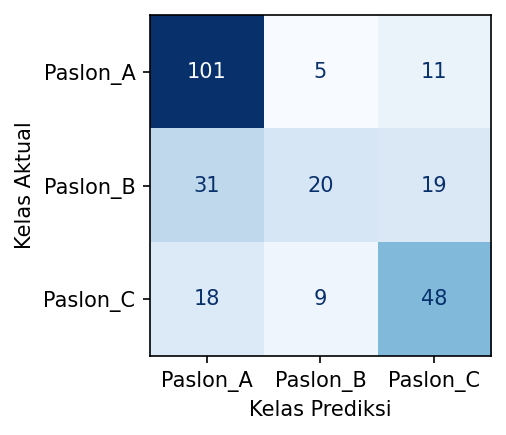

In [ ]:
fig, ax = plt.subplots(figsize=(5, 3), dpi=150)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=labels)
disp.plot(values_format=".0f", cmap="Blues", colorbar=False, ax=ax)

ax.set_xlabel("Kelas Prediksi")
ax.set_ylabel("Kelas Aktual")

plt.tight_layout()
plt.show()

### Prediksi

Sebagai contoh, dilakukan prediksi menggunakan data baru sebagai berikut:

In [ ]:
data_baru = {
    "age": 21,
    "interest": 4,              # misal skala 1–5
    "online": 5,                # misal jam online per hari
    "first_1": 1,               # pemilih pertama kali
    "job_stable_Yes": 0,        # pekerjaan belum stabil
    "community_Yes": 1,         # aktif komunitas
    "info_source_OnlineNews": 0,
    "info_source_SocialMedia": 1,
    "info_source_TV": 0,
    "edu_Secondary": 0,
    "edu_Tertiary": 1,          # pendidikan tinggi
}

X_new = pd.DataFrame([data_baru])

y_pred_new = model_svm.predict(X_new)
y_proba_new = model_svm.predict_proba(X_new)

print("Prediksi pilihan paslon :", y_pred_new[0])
print("Prob tiap kelas         :", y_proba_new[0])

Prediksi pilihan paslon : Paslon_A
Prob tiap kelas         : [9.99999850e-01 1.00000015e-07 5.00000075e-08]


## Random Forest (Bagging)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

### Training

#### Tanpa tuning parameter

In [ ]:
# Membuat model
model_rfc = RandomForestClassifier(max_depth=10)
# Train model
model_rfc.fit(X_train_std, y_train)

RandomForestClassifier(max_depth=10)

#### Dengan tuning parameter

In [ ]:
param_rfc = {
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [5, 10],
}

grid_rfc = GridSearchCV(
    RandomForestClassifier(),
    param_rfc,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

grid_rfc.fit(X_train_std, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(), n_jobs=-1,
             param_grid={'max_depth': [None, 5, 10, 20],
                         'min_samples_split': [5, 10]},
             scoring='accuracy')

In [ ]:
print("Best params :", grid_rfc.best_params_)
print("Best CV acc :", grid_rfc.best_score_)

Best params : {'max_depth': 5, 'min_samples_split': 5}
Best CV acc : 0.6772175193227825


In [ ]:
model_rfc = RandomForestClassifier(**grid_rfc.best_params_)
model_rfc.fit(X_train_std, y_train)

RandomForestClassifier(max_depth=5, min_samples_split=5)

### Evaluasi

In [ ]:
y_pred_rfc_train = model_rfc.predict(X_train_std)
y_pred_rfc_test  = model_rfc.predict(X_test_std)

train_acc_rfc = accuracy_score(y_pred_rfc_train, y_train)
test_acc_rfc = accuracy_score(y_pred_rfc_test, y_test)

print(f"Train Accuracy : {train_acc_rfc:.04f}")
print(f"Test Accuracy  : {test_acc_rfc:.04f}")

Train Accuracy : 0.7251
Test Accuracy  : 0.6489


In [ ]:
labels = np.unique(y_test)
cm_rfc = confusion_matrix(y_test, y_pred_rfc_test, labels=labels)
cm_rfc

array([[102,   3,  12],
       [ 33,  18,  19],
       [ 18,   7,  50]])

In [ ]:
print("Sensitivity & Specificity per class:")

sensitivity_rfc = []
specificity_rfc = []

for i, cls in enumerate(labels):
    tp = cm_rfc[i, i]
    fn = cm_rfc[i, :].sum() - tp
    fp = cm_rfc[:, i].sum() - tp
    tn = cm_rfc.sum() - tp - fn - fp

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    sensitivity_rfc += [sensitivity]
    specificity_rfc += [specificity]

    print(f"Jika kategori {cls} adalah kelas positif -> Sensitivity: {sensitivity:.3f} | Specificity: {specificity:.3f}")

Sensitivity & Specificity per class:
Jika kategori Paslon_A adalah kelas positif -> Sensitivity: 0.872 | Specificity: 0.648
Jika kategori Paslon_B adalah kelas positif -> Sensitivity: 0.257 | Specificity: 0.948
Jika kategori Paslon_C adalah kelas positif -> Sensitivity: 0.667 | Specificity: 0.834


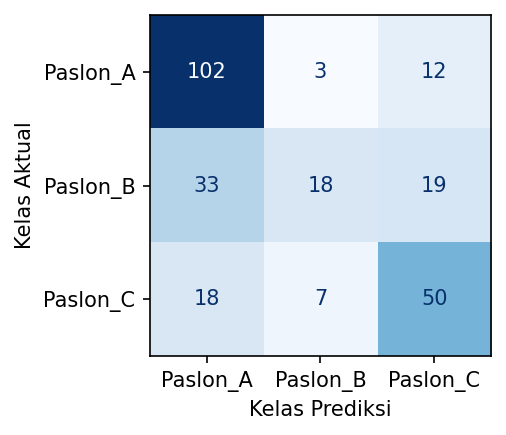

In [ ]:
fig, ax = plt.subplots(figsize=(5, 3), dpi=150)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_rfc, display_labels=labels)
disp.plot(values_format=".0f", cmap="Blues", colorbar=False, ax=ax)

ax.set_xlabel("Kelas Prediksi")
ax.set_ylabel("Kelas Aktual")

plt.tight_layout()
plt.show()

### Prediksi

Sebagai contoh, dilakukan prediksi menggunakan data baru sebagai berikut:

In [ ]:
data_baru = {
    "age": 21,
    "interest": 4,              # misal skala 1–5
    "online": 5,                # misal jam online per hari
    "first_1": 1,               # pemilih pertama kali
    "job_stable_Yes": 0,        # pekerjaan belum stabil
    "community_Yes": 1,         # aktif komunitas
    "info_source_OnlineNews": 0,
    "info_source_SocialMedia": 1,
    "info_source_TV": 0,
    "edu_Secondary": 0,
    "edu_Tertiary": 1,          # pendidikan tinggi
}

X_new = pd.DataFrame([data_baru])

y_pred_new = model_rfc.predict(X_new)
y_proba_new = model_rfc.predict_proba(X_new)

print("Prediksi pilihan paslon :", y_pred_new[0])
print("Prob tiap kelas         :", y_proba_new[0])

Prediksi pilihan paslon : Paslon_B
Prob tiap kelas         : [0.28604261 0.36564651 0.34831088]


## Gradient Boosting

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

### Training

#### Tanpa tuning parameter

In [ ]:
# Membuat model
model_gbt = GradientBoostingClassifier(learning_rate=0.05)
# Train model
model_gbt.fit(X_train_std, y_train)

GradientBoostingClassifier(learning_rate=0.05)

#### Dengan tuning parameter

In [ ]:
param_gbt = {
    "learning_rate": [0.01, 0.1],
}

grid_gbt = GridSearchCV(
    GradientBoostingClassifier(),
    param_gbt,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

grid_gbt.fit(X_train_std, y_train)

GridSearchCV(cv=5, estimator=GradientBoostingClassifier(), n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.1]}, scoring='accuracy')

In [ ]:
print("Best params :", grid_gbt.best_params_)
print("Best CV acc :", grid_gbt.best_score_)

Best params : {'learning_rate': 0.01}
Best CV acc : 0.6724282296650717


In [ ]:
model_gbt = GradientBoostingClassifier(**grid_gbt.best_params_)
model_gbt.fit(X_train_std, y_train)

GradientBoostingClassifier(learning_rate=0.01)

### Evaluasi

In [ ]:
y_pred_gbt_train = model_gbt.predict(X_train_std)
y_pred_gbt_test  = model_gbt.predict(X_test_std)

train_acc_gbt = accuracy_score(y_pred_gbt_train, y_train)
test_acc_gbt = accuracy_score(y_pred_gbt_test, y_test)

print(f"Train Accuracy : {train_acc_gbt:.04f}")
print(f"Test Accuracy  : {test_acc_gbt:.04f}")

Train Accuracy : 0.6973
Test Accuracy  : 0.6221


In [ ]:
labels = np.unique(y_test)
cm_gbt = confusion_matrix(y_test, y_pred_gbt_test, labels=labels)
cm_gbt

array([[104,   2,  11],
       [ 43,  11,  16],
       [ 24,   3,  48]])

In [ ]:
print("Sensitivity & Specificity per class:")

sensitivity_gbt = []
specificity_gbt = []

for i, cls in enumerate(labels):
    tp = cm_gbt[i, i]
    fn = cm_gbt[i, :].sum() - tp
    fp = cm_gbt[:, i].sum() - tp
    tn = cm_gbt.sum() - tp - fn - fp

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    sensitivity_gbt += [sensitivity]
    specificity_gbt += [specificity]

    print(f"Jika kategori {cls} adalah kelas positif -> Sensitivity: {sensitivity:.3f} | Specificity: {specificity:.3f}")

Sensitivity & Specificity per class:
Jika kategori Paslon_A adalah kelas positif -> Sensitivity: 0.889 | Specificity: 0.538
Jika kategori Paslon_B adalah kelas positif -> Sensitivity: 0.157 | Specificity: 0.974
Jika kategori Paslon_C adalah kelas positif -> Sensitivity: 0.640 | Specificity: 0.856


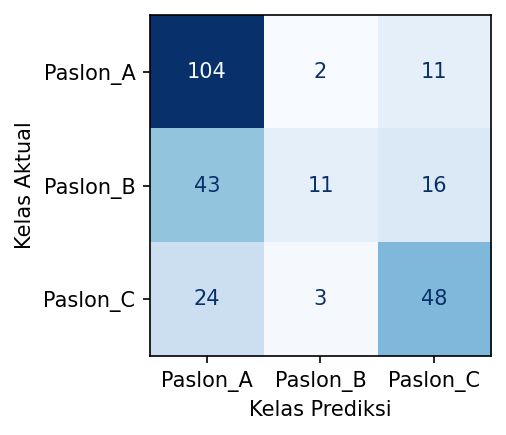

In [ ]:
fig, ax = plt.subplots(figsize=(5, 3), dpi=150)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_gbt, display_labels=labels)
disp.plot(values_format=".0f", cmap="Blues", colorbar=False, ax=ax)

ax.set_xlabel("Kelas Prediksi")
ax.set_ylabel("Kelas Aktual")

plt.tight_layout()
plt.show()

### Prediksi

Sebagai contoh, dilakukan prediksi menggunakan data baru sebagai berikut:

In [ ]:
data_baru = {
    "age": 21,
    "interest": 4,              # misal skala 1–5
    "online": 5,                # misal jam online per hari
    "first_1": 1,               # pemilih pertama kali
    "job_stable_Yes": 0,        # pekerjaan belum stabil
    "community_Yes": 1,         # aktif komunitas
    "info_source_OnlineNews": 0,
    "info_source_SocialMedia": 1,
    "info_source_TV": 0,
    "edu_Secondary": 0,
    "edu_Tertiary": 1,          # pendidikan tinggi
}

X_new = pd.DataFrame([data_baru])

y_pred_new = model_gbt.predict(X_new)
y_proba_new = model_gbt.predict_proba(X_new)

print("Prediksi pilihan paslon :", y_pred_new[0])
print("Prob tiap kelas         :", y_proba_new[0])

Prediksi pilihan paslon : Paslon_C
Prob tiap kelas         : [0.25185175 0.17606474 0.57208351]


# PERBANDINGAN METRIK EVALUASI

In [ ]:
model_names = ['k-NN', 'Decision Tree', 'SVM', 'Random Forest', 'Gradient Boosting']
model_accuracies = [test_acc_knn, test_acc_dct, test_acc_svm, test_acc_rfc, test_acc_gbt]

print('Perbandingan Model Berdasarkan Akurasi')
comparison = pd.DataFrame({
    'Model': model_names,
    'Akurasi': [f'{a:.6f}' for a in model_accuracies]})
comparison.sort_values(by='Akurasi').reset_index(drop=True)

Perbandingan Model Berdasarkan Akurasi


,Model,Akurasi
0,Decision Tree,0.614504
1,Gradient Boosting,0.622137
2,k-NN,0.645038
3,SVM,0.645038
4,Random Forest,0.645038


In [ ]:
model_sensitivity = [sensitivity_knn, sensitivity_dct, sensitivity_svm, sensitivity_rfc, sensitivity_gbt]
model_specificity = [specificity_knn, specificity_dct, specificity_svm, specificity_rfc, specificity_gbt]

print("Perbandingan Model Berdasarkan Sensitivitas dan Spesifisitas")

for i, cls in enumerate(labels):
    print(f"\nJika kategori '{cls}' menjadi kelas positif:")
    comparison = pd.DataFrame({
        "Model": model_names,
        "Spesifisitas": [f'{s[i]:.6f}' for s in model_specificity],
        "Sensitivitas": [f'{s[i]:.6f}' for s in model_sensitivity],
    })
    display(comparison)

Perbandingan Model Berdasarkan Sensitivitas dan Spesifisitas

Jika kategori 'Paslon_A' menjadi kelas positif:


,Model,Spesifisitas,Sensitivitas
0,k-NN,0.579310,0.914530
1,Decision Tree,0.689655,0.803419
2,SVM,0.662069,0.863248
3,Random Forest,0.641379,0.863248
4,Gradient Boosting,0.537931,0.888889



Jika kategori 'Paslon_B' menjadi kelas positif:


,Model,Spesifisitas,Sensitivitas
0,k-NN,0.958333,0.242857
1,Decision Tree,0.885417,0.314286
2,SVM,0.927083,0.285714
3,Random Forest,0.947917,0.257143
4,Gradient Boosting,0.973958,0.157143



Jika kategori 'Paslon_C' menjadi kelas positif:


,Model,Spesifisitas,Sensitivitas
0,k-NN,0.871658,0.600000
1,Decision Tree,0.818182,0.600000
2,SVM,0.839572,0.640000
3,Random Forest,0.834225,0.666667
4,Gradient Boosting,0.855615,0.640000
